# Low-Cost Multispectral Pipeline for Distinguishing PLA from PET in Resource-Constrained Recycling

## Notebook 1: Sensor simulation on the Zenodo NIR/SWIR plastic-substrate library

**Purpose.** Estimate how well a low-cost spectral sensor could separate PLA from PET, using a public laboratory
spectral library and simulating what each candidate chip (AS7265x, AS7421) would actually measure.

**Dataset.** Holt, Z. (2024). *NIR/SWIR Spectral Library of Plastic-Substrate Mixtures* (version 2) [Data set]. Zenodo.
https://doi.org/10.5281/zenodo.14419753, licence CC BY 4.0. The record lists a related journal article, https://doi.org/10.1016/j.envpol.2025.126426.
Files used: `__Mean_Spectra_Reflectance.csv` and `__Mean_Spectra_Absorption_der1.csv` (850 to 2400 nm, 1 nm step).

**Questions this notebook answers**
1. How is the dataset organised, and what exactly is in it for PET and PLA?
2. Where do PET and PLA differ spectrally, and how much of that lies inside each chip's range?
3. How well can a classifier separate them when it is tested on a background it has never seen?
4. Does the narrower AS7265x or the wider AS7421 do better, and is the difference larger than chance?

**Evaluation protocol (decided before looking at results).**
- Leave-one-substrate-out cross-validation. The model is always tested on a substrate (soil, cement, oak leaf powder or water) it was not trained on.
- Primary configuration: logistic regression on SNV-normalised simulated channels. Random forest is reported as a secondary model.
- Every configuration that was run is reported, not only the best ones.
- Accuracy is shown with the number of samples and a 95% Wilson confidence interval, plus a label-permutation test against chance.

**Read before quoting any number.** The library holds one pure PET spectrum and one pure PLA spectrum. All other PET and PLA rows are
those same two plastics diluted into six backgrounds. The spectra were also pre-processed by the authors (continuum removal, SNV, smoothing).
Results therefore show separability across backgrounds under laboratory conditions, not performance on real bottles, cups or colours,
and not performance of a physical sensor.

## 1. Setup

In [1]:
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore")

# Paths and constants
DATA_DIR = "data"
RESULTS_DIR = "results"
REFLECTANCE_CSV = os.path.join(DATA_DIR, "__Mean_Spectra_Reflectance.csv")
DER1_CSV = os.path.join(DATA_DIR, "__Mean_Spectra_Absorption_der1.csv")
RANDOM_STATE = 0
N_PERMUTATIONS = 100            # label permutations used for the chance test
OPERATIONAL_MIN_CONC = 15.0     # percent plastic, defines the "operational" scope in Stage 2
SRS_TARGET_ACCURACY = 0.85      # target stated in the SRS, drawn as a reference line only

os.makedirs(RESULTS_DIR, exist_ok=True)

# Plot style
COL = {"PET": "#c0392b", "PLA": "#1b9e8f", "AS7265x": "#e08e0b", "AS7421": "#2c6fbb", "Full": "#555555"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 11, "axes.labelsize": 10,
})

def save_fig(name):
    path = os.path.join(RESULTS_DIR, name)
    plt.savefig(path, bbox_inches="tight")
    print("saved:", path)

## 2. Load the data and decode the column names

Each column is one prepared sample, named `<substrate>_<plastic>_<concentration>`.
Concentration is percent plastic by weight, written with `X` for the decimal point (`0X15` means 0.15%).
Substrates: `Bu5`, `W6`, `TG` (soils), `C` (crushed cement), `V` (oak leaf powder), `DIW` (deionised water).

In [2]:
for path in (REFLECTANCE_CSV, DER1_CSV):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing {path}. Download it from the Zenodo record and place it in the '{DATA_DIR}' folder.")

refl = pd.read_csv(REFLECTANCE_CSV)
der1 = pd.read_csv(DER1_CSV)

# Both files must describe the same samples on the same wavelength grid
assert list(refl.columns) == list(der1.columns), "The two files have different columns"
assert np.allclose(refl["wavelength"], der1["wavelength"]), "The two files use different wavelength grids"

wl = refl["wavelength"].to_numpy(dtype=float)
print(f"Wavelength grid: {wl.min():.0f} to {wl.max():.0f} nm, step {np.diff(wl).mean():.0f} nm, {len(wl)} points")
print(f"Sample columns: {refl.shape[1] - 1}")
print("Missing values:", int(refl.isna().sum().sum()), "(reflectance),", int(der1.isna().sum().sum()), "(derivative)")

Wavelength grid: 850 to 2400 nm, step 1 nm, 1551 points
Sample columns: 228
Missing values: 0 (reflectance), 0 (derivative)


In [3]:
# Decode "<substrate>_<plastic>_<concentration>". The plastic part is empty for substrate-only (0%) columns,
# and the substrate part is empty for the pure-plastic (100%) columns.
PATTERN = re.compile(r"^(?P<substrate>.*?)_(?P<plastic>PE|PET|PLA|PP|PVC|SBR)?_(?P<conc>.+)$")

records = []
for col in refl.columns[1:]:
    m = PATTERN.match(col)
    if m is None:
        raise ValueError(f"Column name not understood: {col}")
    records.append({
        "sample_id": col,
        "substrate": m["substrate"] if m["substrate"] else "pure",
        "plastic": m["plastic"] if m["plastic"] else "none",
        "conc_pct": float(m["conc"].replace("X", ".")),
    })
meta = pd.DataFrame(records)

print("Samples per plastic (all six plastics plus substrate-only):")
print(meta["plastic"].value_counts().to_string())
print("\nPET and PLA samples per substrate and concentration:")
subset = meta[meta["plastic"].isin(["PET", "PLA"])]
print(pd.crosstab([subset["plastic"], subset["substrate"]], subset["conc_pct"]).to_string())

Samples per plastic (all six plastics plus substrate-only):
plastic
PE      37
PET     37
PLA     37
PP      37
PVC     37
SBR     37
none     6

PET and PLA samples per substrate and concentration:
conc_pct           0.15    0.50    1.50    5.00    15.00   50.00   100.00
plastic substrate                                                        
PET     Bu5             1       1       1       1       1       1       0
        C               1       1       1       1       1       1       0
        DIW             1       1       1       1       1       1       0
        TG              1       1       1       1       1       1       0
        V               1       1       1       1       1       1       0
        W6              1       1       1       1       1       1       0
        pure            0       0       0       0       0       0       1
PLA     Bu5             1       1       1       1       1       1       0
        C               1       1       1       1       1    

**What the table shows.** For each plastic there are 36 mixtures (six substrates times six concentrations from 0.15% to 50%) plus a single
pure-plastic sample, labelled `pure`. The pure samples have no substrate. This is why the evaluation below uses `pure` as its own seventh group.

In [4]:
# Keep only the two target classes and build the matrices used from here on
samples = meta[meta["plastic"].isin(["PET", "PLA"])].reset_index(drop=True)
ids = samples["sample_id"].tolist()

X_refl = refl[ids].to_numpy().T          # shape: (samples, wavelengths), lab reflectance
X_der1 = der1[ids].to_numpy().T          # shape: (samples, wavelengths), lab first derivative of absorption
y = (samples["plastic"] == "PLA").astype(int).to_numpy()      # 0 = PET, 1 = PLA
groups = samples["substrate"].to_numpy()
conc = samples["conc_pct"].to_numpy()

print("Samples:", len(samples), "| PET:", int((y == 0).sum()), "| PLA:", int((y == 1).sum()))
print("Groups for cross-validation:", sorted(set(groups)))
samples.head(8)

Samples: 74 | PET: 37 | PLA: 37
Groups for cross-validation: ['Bu5', 'C', 'DIW', 'TG', 'V', 'W6', 'pure']


,sample_id,substrate,plastic,conc_pct
0,Bu5_PET_0X15,Bu5,PET,0.15
1,Bu5_PET_0X5,Bu5,PET,0.50
2,Bu5_PET_1X5,Bu5,PET,1.50
3,Bu5_PET_5,Bu5,PET,5.00
4,Bu5_PET_15,Bu5,PET,15.00
5,Bu5_PET_50,Bu5,PET,50.00
6,Bu5_PLA_0X15,Bu5,PLA,0.15
7,Bu5_PLA_0X5,Bu5,PLA,0.50


## 3. Exploratory analysis: where do PET and PLA differ?

saved: results/01_pure_spectra_full_range.png


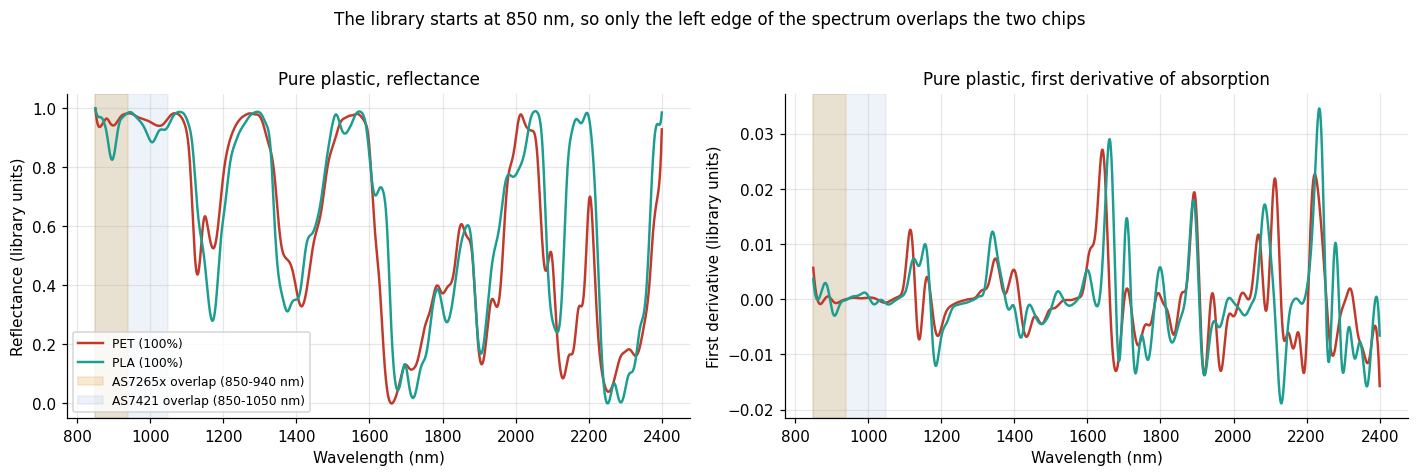

In [5]:
pure_pet = X_refl[(samples["sample_id"] == "_PET_100").to_numpy()][0]
pure_pla = X_refl[(samples["sample_id"] == "_PLA_100").to_numpy()][0]
pure_pet_d = X_der1[(samples["sample_id"] == "_PET_100").to_numpy()][0]
pure_pla_d = X_der1[(samples["sample_id"] == "_PLA_100").to_numpy()][0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (title, pet, pla, ylab) in zip(axes, [
        ("Pure plastic, reflectance", pure_pet, pure_pla, "Reflectance (library units)"),
        ("Pure plastic, first derivative of absorption", pure_pet_d, pure_pla_d, "First derivative (library units)")]):
    ax.plot(wl, pet, color=COL["PET"], lw=1.6, label="PET (100%)")
    ax.plot(wl, pla, color=COL["PLA"], lw=1.6, label="PLA (100%)")
    ax.axvspan(850, 940, color=COL["AS7265x"], alpha=0.18, label="AS7265x overlap (850-940 nm)")
    ax.axvspan(850, 1050, color=COL["AS7421"], alpha=0.08, label="AS7421 overlap (850-1050 nm)")
    ax.set_title(title); ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel(ylab)
axes[0].legend(fontsize=8, loc="best")
plt.suptitle("The library starts at 850 nm, so only the left edge of the spectrum overlaps the two chips", y=1.02, fontsize=11)
plt.tight_layout(); save_fig("01_pure_spectra_full_range.png"); plt.show()

saved: results/02_window_by_concentration.png


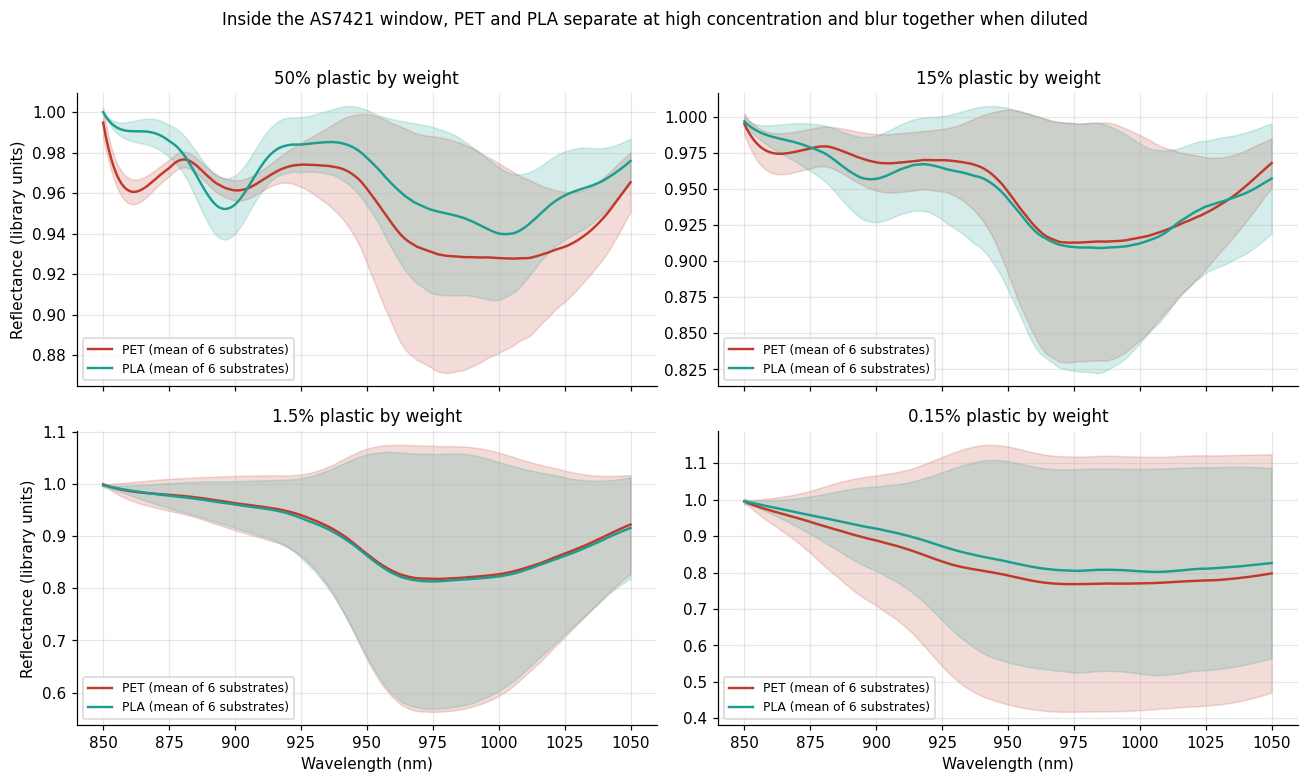

In [6]:
# Same comparison inside the 850-1050 nm window, at four concentrations, averaged over the six real substrates
window = (wl >= 850) & (wl <= 1050)
real_sub = [s for s in sorted(set(groups)) if s != "pure"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, c in zip(axes.ravel(), [50.0, 15.0, 1.5, 0.15]):
    for plastic, colour in [("PET", COL["PET"]), ("PLA", COL["PLA"])]:
        sel = ((samples["plastic"] == plastic) & (samples["conc_pct"] == c) & samples["substrate"].isin(real_sub)).to_numpy()
        block = X_refl[sel][:, window]
        mean, sd = block.mean(0), block.std(0)
        ax.plot(wl[window], mean, color=colour, lw=1.6, label=f"{plastic} (mean of {sel.sum()} substrates)")
        ax.fill_between(wl[window], mean - sd, mean + sd, color=colour, alpha=0.18)
    ax.set_title(f"{c:g}% plastic by weight")
    ax.legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Wavelength (nm)")
for ax in axes[:, 0]:
    ax.set_ylabel("Reflectance (library units)")
plt.suptitle("Inside the AS7421 window, PET and PLA separate at high concentration and blur together when diluted", y=1.01, fontsize=11)
plt.tight_layout(); save_fig("02_window_by_concentration.png"); plt.show()

**Reading the plots.** The pure spectra differ across the full range, and most of the large differences lie beyond 1050 nm, out of reach of both chips.
Inside the chips' window the clearest visible feature is a dip near 900 nm in pure PLA that PET does not show.
In the mixtures, the two plastics are still distinguishable at 50%, much less at 15%, and the mean curves are almost identical at 1.5% and 0.15%.
The broad dip near 970 nm in the diluted samples appears for both plastics, so it comes from the background (probably water absorption), not from the plastic.
The shaded bands (one standard deviation across the six backgrounds) show how strongly the substrate alone moves the spectrum.

## 4. Simulating the two chips

A real sensor does not return one value per nanometre. Each channel integrates light over a band.
For each chip, every library spectrum is converted into what its channels would measure, using a Gaussian response with the chip's nominal bandwidth.

- **AS7265x:** 18 channels from 410 to 940 nm, about 20 nm FWHM each. Nominal centres are listed below, so check them against the datasheet before quoting.
- **AS7421:** about 61 channels spaced evenly from 750 to 1050 nm, about 10 nm FWHM. This layout is an approximation of the datasheet description.

The library starts at 850 nm, so a channel is only simulated when its whole band lies inside the library range.
Everything below that is simply unavailable in this dataset.

In [7]:
AS7265X_CENTRES = np.array([410, 435, 460, 485, 510, 535, 560, 585, 610, 645, 680, 705, 730, 760, 810, 860, 900, 940], dtype=float)
AS7265X_FWHM = 20.0
AS7421_CENTRES = np.linspace(750, 1050, 61)
AS7421_FWHM = 10.0

def response_matrix(wavelengths, centres, fwhm):
    """Gaussian band responses (rows = channels, rows sum to 1). Channels not fully covered by the data are dropped."""
    w = np.exp(-4 * np.log(2) * (wavelengths[None, :] - centres[:, None]) ** 2 / fwhm ** 2)
    covered = (wavelengths.min() <= centres - fwhm / 2) & (wavelengths.max() >= centres + fwhm / 2)
    w = w[covered]
    return w / w.sum(axis=1, keepdims=True), centres[covered]

R_265, centres_265 = response_matrix(wl, AS7265X_CENTRES, AS7265X_FWHM)
R_421, centres_421 = response_matrix(wl, AS7421_CENTRES, AS7421_FWHM)

channel_table = pd.DataFrame({
    "chip": ["AS7265x", "AS7421"],
    "channels on the chip": [len(AS7265X_CENTRES), len(AS7421_CENTRES)],
    "channels simulated here": [len(centres_265), len(centres_421)],
    "simulated centres (nm)": [", ".join(f"{c:.0f}" for c in centres_265),
                               f"{centres_421.min():.0f} to {centres_421.max():.0f}, every 5"],
})
print(channel_table.to_string(index=False))

   chip  channels on the chip  channels simulated here simulated centres (nm)
AS7265x                    18                        3          860, 900, 940
 AS7421                    61                       40   855 to 1050, every 5


**Important consequence.** Only 3 of the 18 AS7265x channels (860, 900, 940 nm) can be simulated from this library, because the other 15 lie below 850 nm.
The AS7421 keeps 40 of its channels. Any comparison of the chips here is therefore a comparison on the part of the spectrum the library covers,
not a full comparison of the chips.

saved: results/03_simulated_channels.png


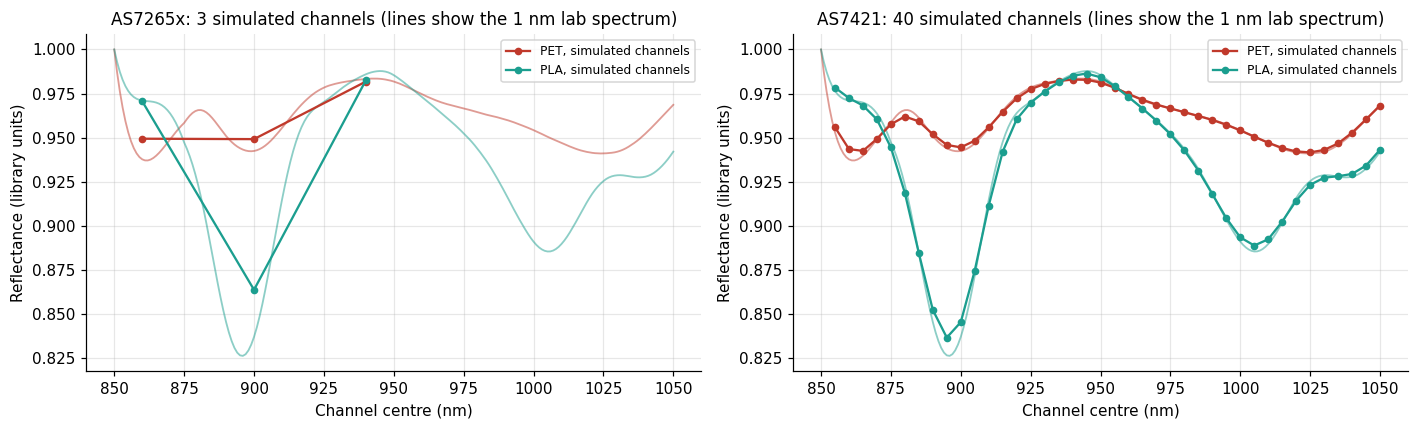

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, R, centres, colour) in zip(axes, [("AS7265x", R_265, centres_265, COL["AS7265x"]),
                                                  ("AS7421", R_421, centres_421, COL["AS7421"])]):
    ax.plot(wl[window], pure_pet[window], color=COL["PET"], lw=1.2, alpha=0.5)
    ax.plot(wl[window], pure_pla[window], color=COL["PLA"], lw=1.2, alpha=0.5)
    ax.plot(centres, R @ pure_pet, "o-", color=COL["PET"], ms=4, label="PET, simulated channels")
    ax.plot(centres, R @ pure_pla, "o-", color=COL["PLA"], ms=4, label="PLA, simulated channels")
    ax.set_title(f"{name}: {len(centres)} simulated channels (lines show the 1 nm lab spectrum)")
    ax.set_xlabel("Channel centre (nm)"); ax.set_ylabel("Reflectance (library units)"); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("03_simulated_channels.png"); plt.show()

## 5. Evaluation framework

The helpers below are used by every experiment, so all numbers share the same protocol.

- **Leave-one-substrate-out (LOSO).** Each fold holds out one whole group (Bu5, W6, TG, C, V, DIW, or the two `pure` samples) and trains on the rest. Predictions from all folds are pooled, so every sample is predicted exactly once, by a model that never saw its substrate.
- **Confidence interval.** 95% Wilson interval on the pooled accuracy. It treats samples as independent, which they are not (the same plastic recurs in every substrate), so the true uncertainty is larger.
- **Chance test.** Labels are shuffled within each substrate group, and the full LOSO procedure is repeated. The p-value is the share of shuffles that did at least as well as the real labels.

In [9]:
LOGO = LeaveOneGroupOut()

def snv(a):
    """Standard Normal Variate per spectrum: removes overall brightness and scale, keeps shape."""
    a = np.asarray(a, dtype=float)
    return (a - a.mean(axis=1, keepdims=True)) / (a.std(axis=1, keepdims=True) + 1e-12)

def wilson_interval(k, n, z=1.96):
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half

def make_logreg():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000))

def make_forest():
    return RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)

MODELS = {"LogReg": make_logreg, "RandomForest": make_forest}

def loso_predict(features, labels, grp, model_factory):
    return cross_val_predict(model_factory(), features, labels, groups=grp, cv=LOGO)

def permutation_p_value(features, labels, grp, model_factory, observed_accuracy, n_perm=N_PERMUTATIONS, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    hits = 0
    for _ in range(n_perm):
        shuffled = labels.copy()
        for g in np.unique(grp):
            idx = np.where(grp == g)[0]
            shuffled[idx] = rng.permutation(labels[idx])
        pred = loso_predict(features, shuffled, grp, model_factory)
        hits += accuracy_score(shuffled, pred) >= observed_accuracy
    return (hits + 1) / (n_perm + 1)

In [10]:
# Feature sets. Each entry builds a feature matrix from the reflectance matrix R and the lab-derivative matrix D.
# "kind" says what the entry represents, so results are never mistaken for a chip simulation when they are not.
FEATURE_SETS = {
    # Lab data at full resolution: not available to either chip, shown as an upper reference
    "Full 850-2400 nm, reflectance (SNV)":     dict(kind="Lab reference", build=lambda R, D: snv(R)),
    "Full 850-2400 nm, derivative file":       dict(kind="Lab reference", build=lambda R, D: D),
    # What the first notebook did: slice 1 nm readings. Kept for comparison, not a chip simulation
    "1 nm slice 850-940, reflectance (SNV)":   dict(kind="Raw slice (not a chip)", build=lambda R, D: snv(R[:, (wl >= 850) & (wl <= 940)])),
    "1 nm slice 850-1050, reflectance (SNV)":  dict(kind="Raw slice (not a chip)", build=lambda R, D: snv(R[:, (wl >= 850) & (wl <= 1050)])),
    # Simulated chip channels, reflectance
    "AS7265x sim, channels (SNV)":             dict(kind="Chip simulation", build=lambda R, D: snv(R @ R_265.T)),
    "AS7421 sim, channels (SNV)":              dict(kind="Chip simulation", build=lambda R, D: snv(R @ R_421.T)),
    # Simulated chip channels, derivative features
    "AS7265x sim, channel differences":        dict(kind="Chip simulation", build=lambda R, D: np.diff(R @ R_265.T, axis=1)),
    "AS7421 sim, channel differences":         dict(kind="Chip simulation", build=lambda R, D: np.diff(R @ R_421.T, axis=1)),
    "AS7265x sim, derivative file band-avg":   dict(kind="Chip simulation (optimistic)", build=lambda R, D: D @ R_265.T),
    "AS7421 sim, derivative file band-avg":    dict(kind="Chip simulation (optimistic)", build=lambda R, D: D @ R_421.T),
}

REFLECTANCE_SETS = [n for n in FEATURE_SETS if "derivative" not in n and "differences" not in n]
DERIVATIVE_SETS = [n for n in FEATURE_SETS if "derivative" in n or "differences" in n]

stored_predictions = {}   # (stage, feature set, model) -> predictions, reused for the later analysis plots

def run_grid(stage_name, mask, feature_names, with_permutation=True):
    rows = []
    for fname in feature_names:
        spec = FEATURE_SETS[fname]
        F = spec["build"](X_refl[mask], X_der1[mask])
        for mname, factory in MODELS.items():
            pred = loso_predict(F, y[mask], groups[mask], factory)
            stored_predictions[(stage_name, fname, mname)] = (mask, pred)
            k = int((pred == y[mask]).sum()); n = int(mask.sum())
            acc = k / n
            lo, hi = wilson_interval(k, n)
            p_perm = np.nan
            if with_permutation and mname == "LogReg" and spec["kind"].startswith("Chip"):
                p_perm = permutation_p_value(F, y[mask], groups[mask], factory, acc)
            rows.append({
                "stage": stage_name, "feature set": fname, "kind": spec["kind"], "model": mname, "n_features": F.shape[1],
                "n_samples": n, "correct": k, "accuracy": acc, "ci_low": lo, "ci_high": hi,
                "macro_F1": f1_score(y[mask], pred, average="macro"), "perm_p": p_perm,
            })
    return pd.DataFrame(rows)

def show(df):
    out = df.copy()
    out["accuracy (k/n)"] = [f"{a:.3f} ({k}/{n})" for a, k, n in zip(out.accuracy, out.correct, out.n_samples)]
    out["95% CI"] = [f"{lo:.2f} to {hi:.2f}" for lo, hi in zip(out.ci_low, out.ci_high)]
    out["macro-F1"] = out.macro_F1.round(3)
    out["chance p"] = out.perm_p.map(lambda v: "" if np.isnan(v) else f"{v:.3f}")
    cols = ["feature set", "kind", "model", "n_features", "accuracy (k/n)", "95% CI", "macro-F1", "chance p"]
    return out[cols].to_string(index=False)

all_mask = np.ones(len(y), dtype=bool)
operational_mask = conc >= OPERATIONAL_MIN_CONC
print("All-concentration scope:", int(all_mask.sum()), "samples | Operational scope (>= {:g}%):".format(OPERATIONAL_MIN_CONC), int(operational_mask.sum()), "samples")

All-concentration scope: 74 samples | Operational scope (>= 15%): 26 samples


## 6. Stage 1: all concentrations, reflectance features

This is the hardest setting. Plastic can make up as little as 0.15% of a sample, mixed into soil, cement, oak leaf powder or water.
The first notebook reported a raw baseline of 56.52% on this kind of data using a random split, which let samples from the same substrate appear in both training and test sets.
Here the test is always an unseen substrate.

In [11]:
stage1 = run_grid("Stage 1: all concentrations", all_mask, REFLECTANCE_SETS)
print(show(stage1))

                           feature set                   kind        model  n_features accuracy (k/n)       95% CI  macro-F1 chance p
   Full 850-2400 nm, reflectance (SNV)          Lab reference       LogReg        1551  0.797 (59/74) 0.69 to 0.87     0.797         
   Full 850-2400 nm, reflectance (SNV)          Lab reference RandomForest        1551  0.838 (62/74) 0.74 to 0.90     0.837         
 1 nm slice 850-940, reflectance (SNV) Raw slice (not a chip)       LogReg          91  0.676 (50/74) 0.56 to 0.77     0.667         
 1 nm slice 850-940, reflectance (SNV) Raw slice (not a chip) RandomForest          91  0.730 (54/74) 0.62 to 0.82     0.728         
1 nm slice 850-1050, reflectance (SNV) Raw slice (not a chip)       LogReg         201  0.662 (49/74) 0.55 to 0.76     0.662         
1 nm slice 850-1050, reflectance (SNV) Raw slice (not a chip) RandomForest         201  0.689 (51/74) 0.58 to 0.78     0.689         
           AS7265x sim, channels (SNV)        Chip simulation 

**Reading the table.** Compare the 1 nm slice rows with the chip-simulation rows. The slices are not what a sensor measures, because they hand the model 91 or 201 near-identical readings.
Rows marked "Chip simulation" are the fair estimate of what each chip could see. The chance p-value tells you whether a result is distinguishable from guessing.

## 7. Stage 2: operational scope (at least 15% plastic)

The SRS targets sorting pieces of plastic, not detecting traces in soil. Stage 2 therefore keeps only samples with at least 15% plastic by weight
(15%, 50% and the pure samples). This **changes the question to an easier one**, so Stage 2 numbers must always be quoted with the 26-sample
size and the scope definition. It is not an algorithmic improvement of the same task.

In [12]:
stage2 = run_grid("Stage 2: operational (>= 15%)", operational_mask, REFLECTANCE_SETS)
print(show(stage2))

                           feature set                   kind        model  n_features accuracy (k/n)       95% CI  macro-F1 chance p
   Full 850-2400 nm, reflectance (SNV)          Lab reference       LogReg        1551  0.923 (24/26) 0.76 to 0.98     0.923         
   Full 850-2400 nm, reflectance (SNV)          Lab reference RandomForest        1551  1.000 (26/26) 0.87 to 1.00     1.000         
 1 nm slice 850-940, reflectance (SNV) Raw slice (not a chip)       LogReg          91  0.923 (24/26) 0.76 to 0.98     0.923         
 1 nm slice 850-940, reflectance (SNV) Raw slice (not a chip) RandomForest          91  0.923 (24/26) 0.76 to 0.98     0.923         
1 nm slice 850-1050, reflectance (SNV) Raw slice (not a chip)       LogReg         201  0.923 (24/26) 0.76 to 0.98     0.923         
1 nm slice 850-1050, reflectance (SNV) Raw slice (not a chip) RandomForest         201  0.885 (23/26) 0.71 to 0.96     0.883         
           AS7265x sim, channels (SNV)        Chip simulation 

## 8. Stage 3: derivative features

Two derivative variants are tested, and they are not equally realistic:

- **Channel differences.** The difference between neighbouring simulated channel values. A microcontroller could compute this directly from the sensor output, so it is a realistic feature.
- **Derivative file, band-averaged.** The library's own derivative spectra, averaged into chip channels. The library computed those derivatives on the full 1 nm laboratory data, which a real sensor cannot do, so treat these rows as optimistic.

In [13]:
stage3_all = run_grid("Stage 1: all concentrations", all_mask, DERIVATIVE_SETS)
stage3_op = run_grid("Stage 2: operational (>= 15%)", operational_mask, DERIVATIVE_SETS)
print("All concentrations (n = {})".format(int(all_mask.sum())))
print(show(stage3_all))
print()
print("Operational scope (n = {})".format(int(operational_mask.sum())))
print(show(stage3_op))

All concentrations (n = 74)
                          feature set                         kind        model  n_features accuracy (k/n)       95% CI  macro-F1 chance p
    Full 850-2400 nm, derivative file                Lab reference       LogReg        1551  0.797 (59/74) 0.69 to 0.87     0.797         
    Full 850-2400 nm, derivative file                Lab reference RandomForest        1551  0.919 (68/74) 0.83 to 0.96     0.919         
     AS7265x sim, channel differences              Chip simulation       LogReg           2  0.568 (42/74) 0.45 to 0.67     0.552    0.069
     AS7265x sim, channel differences              Chip simulation RandomForest           2  0.622 (46/74) 0.51 to 0.72     0.617         
      AS7421 sim, channel differences              Chip simulation       LogReg          39  0.635 (47/74) 0.52 to 0.74     0.633    0.010
      AS7421 sim, channel differences              Chip simulation RandomForest          39  0.689 (51/74) 0.58 to 0.78     0.679         

In [14]:
# Keep every result in one table and save it, so the numbers in the README can be traced back to a file
results = pd.concat([stage1, stage2, stage3_all, stage3_op], ignore_index=True)
results.to_csv(os.path.join(RESULTS_DIR, "all_results.csv"), index=False)
print("Total configurations evaluated:", len(results), "-> saved to", os.path.join(RESULTS_DIR, "all_results.csv"))
print("Because", len(results), "configurations were tried on small samples, the best single score is optimistic by selection.")

Total configurations evaluated: 40 -> saved to results/all_results.csv
Because 40 configurations were tried on small samples, the best single score is optimistic by selection.


## 9. Summary figures

saved: results/04_accuracy_by_stage.png


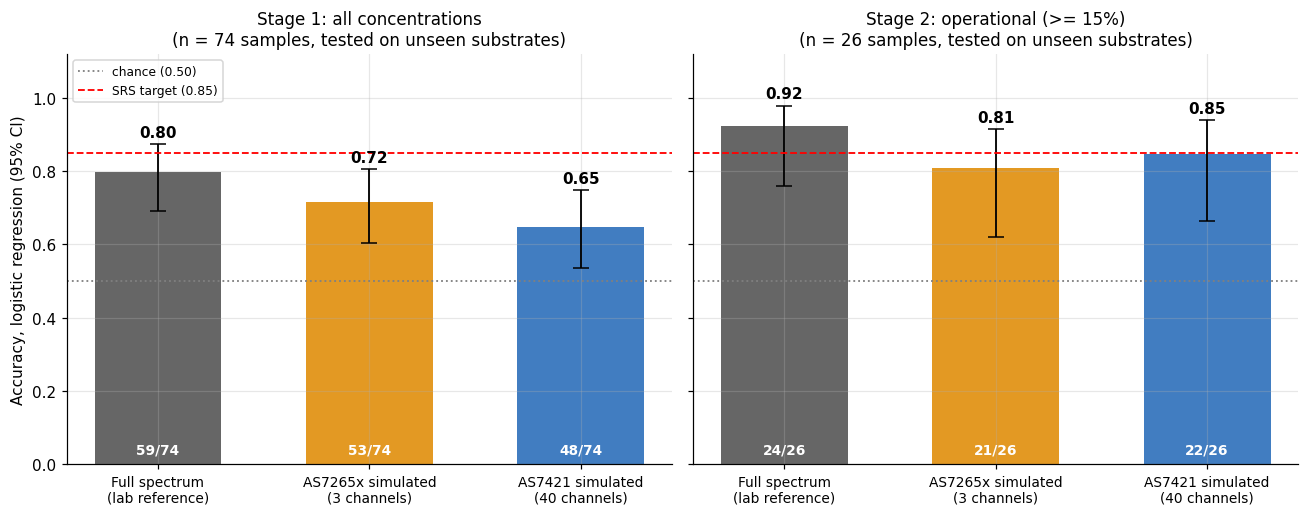

In [15]:
def lookup(stage, feature, model="LogReg"):
    row = results[(results["stage"] == stage) & (results["feature set"] == feature) & (results["model"] == model)].iloc[0]
    return row

STAGE1, STAGE2 = "Stage 1: all concentrations", "Stage 2: operational (>= 15%)"
bar_sets = [("Full 850-2400 nm, reflectance (SNV)", "Full spectrum\n(lab reference)", COL["Full"]),
            ("AS7265x sim, channels (SNV)", "AS7265x simulated\n(3 channels)", COL["AS7265x"]),
            ("AS7421 sim, channels (SNV)", "AS7421 simulated\n(40 channels)", COL["AS7421"])]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, stage in zip(axes, [STAGE1, STAGE2]):
    for i, (fname, label, colour) in enumerate(bar_sets):
        r = lookup(stage, fname)
        ax.bar(i, r.accuracy, color=colour, width=0.6, alpha=0.9)
        ax.errorbar(i, r.accuracy, yerr=[[r.accuracy - r.ci_low], [r.ci_high - r.accuracy]], color="black", capsize=5, lw=1.2)
        ax.text(i, 0.03, f"{int(r.correct)}/{int(r.n_samples)}", ha="center", color="white", fontweight="bold", fontsize=9)
        ax.text(i, r.ci_high + 0.02, f"{r.accuracy:.2f}", ha="center", fontsize=10, fontweight="bold")
    ax.axhline(0.5, color="grey", ls=":", lw=1.2, label="chance (0.50)")
    ax.axhline(SRS_TARGET_ACCURACY, color="red", ls="--", lw=1.2, label=f"SRS target ({SRS_TARGET_ACCURACY:.2f})")
    ax.set_xticks(range(len(bar_sets))); ax.set_xticklabels([b[1] for b in bar_sets], fontsize=9)
    ax.set_title(stage + f"\n(n = {int(lookup(stage, bar_sets[0][0]).n_samples)} samples, tested on unseen substrates)")
    ax.set_ylim(0, 1.12)
axes[0].set_ylabel("Accuracy, logistic regression (95% CI)"); axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); save_fig("04_accuracy_by_stage.png"); plt.show()

saved: results/05_derivative_features.png


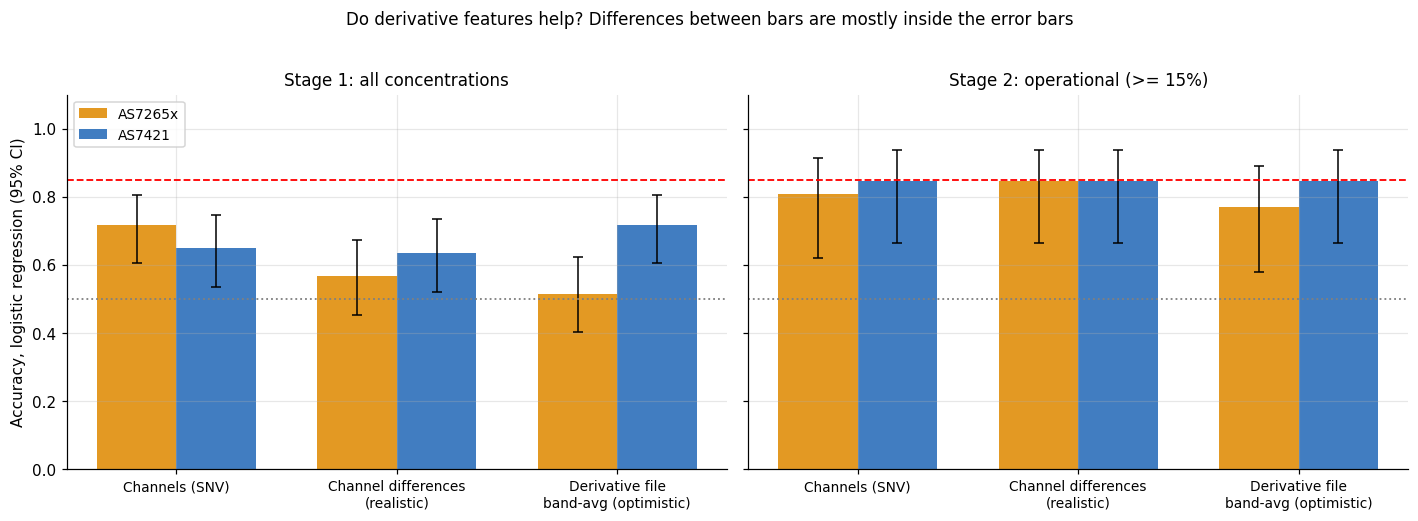

In [16]:
# Derivative features against plain channels, for both chips and both scopes (logistic regression)
pairs = [("AS7265x", "AS7265x sim, channels (SNV)", "AS7265x sim, channel differences", "AS7265x sim, derivative file band-avg"),
         ("AS7421", "AS7421 sim, channels (SNV)", "AS7421 sim, channel differences", "AS7421 sim, derivative file band-avg")]
labels = ["Channels (SNV)", "Channel differences\n(realistic)", "Derivative file\nband-avg (optimistic)"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, stage in zip(axes, [STAGE1, STAGE2]):
    width = 0.36
    for j, (chip, f_ch, f_df, f_dv) in enumerate(pairs):
        vals = [lookup(stage, f) for f in (f_ch, f_df, f_dv)]
        x = np.arange(3) + (j - 0.5) * width
        acc = np.array([v.accuracy for v in vals]); lo = np.array([v.ci_low for v in vals]); hi = np.array([v.ci_high for v in vals])
        ax.bar(x, acc, width=width, color=COL[chip], alpha=0.9, label=chip)
        ax.errorbar(x, acc, yerr=[acc - lo, hi - acc], fmt="none", ecolor="black", capsize=3, lw=1)
    ax.axhline(0.5, color="grey", ls=":", lw=1.2); ax.axhline(SRS_TARGET_ACCURACY, color="red", ls="--", lw=1.2)
    ax.set_xticks(range(3)); ax.set_xticklabels(labels, fontsize=9); ax.set_ylim(0, 1.1); ax.set_title(stage)
axes[0].set_ylabel("Accuracy, logistic regression (95% CI)"); axes[0].legend(fontsize=9, loc="upper left")
plt.suptitle("Do derivative features help? Differences between bars are mostly inside the error bars", y=1.02, fontsize=11)
plt.tight_layout(); save_fig("05_derivative_features.png"); plt.show()

saved: results/06_accuracy_by_concentration.png


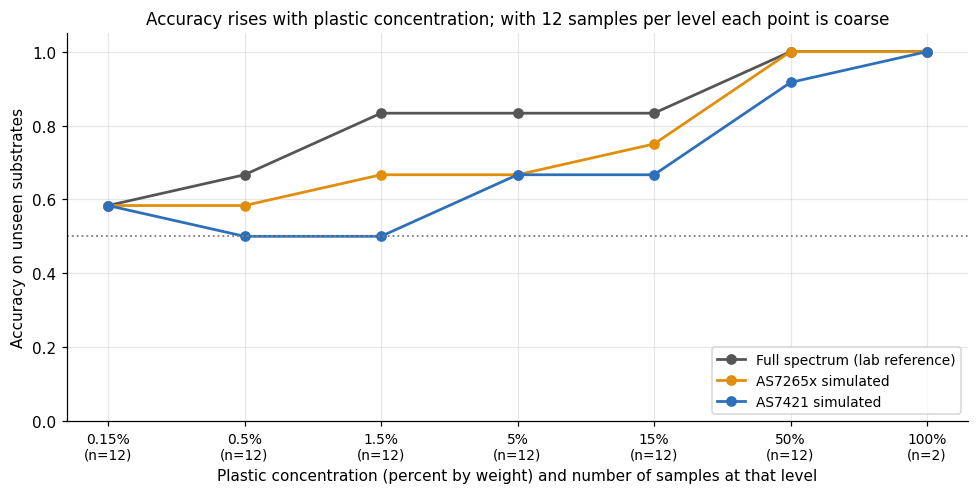

In [17]:
# Accuracy as a function of plastic concentration (Stage 1 predictions, logistic regression)
order = sorted(set(conc))
labels_x = [f"{c:g}%" for c in order]
fig, ax = plt.subplots(figsize=(9, 4.6))
for fname, label, colour in [("Full 850-2400 nm, reflectance (SNV)", "Full spectrum (lab reference)", COL["Full"]),
                             ("AS7265x sim, channels (SNV)", "AS7265x simulated", COL["AS7265x"]),
                             ("AS7421 sim, channels (SNV)", "AS7421 simulated", COL["AS7421"])]:
    mask, pred = stored_predictions[(STAGE1, fname, "LogReg")]
    accs = [(pred[conc[mask] == c] == y[mask][conc[mask] == c]).mean() for c in order]
    ax.plot(range(len(order)), accs, "o-", color=colour, lw=1.8, label=label)
counts = [int((conc == c).sum()) for c in order]
ax.set_xticks(range(len(order))); ax.set_xticklabels([f"{l}\n(n={n})" for l, n in zip(labels_x, counts)], fontsize=9)
ax.axhline(0.5, color="grey", ls=":", lw=1.2)
ax.set_ylim(0, 1.05); ax.set_xlabel("Plastic concentration (percent by weight) and number of samples at that level"); ax.set_ylabel("Accuracy on unseen substrates")
ax.set_title("Accuracy rises with plastic concentration; with 12 samples per level each point is coarse")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout(); save_fig("06_accuracy_by_concentration.png"); plt.show()

saved: results/07_accuracy_by_substrate.png


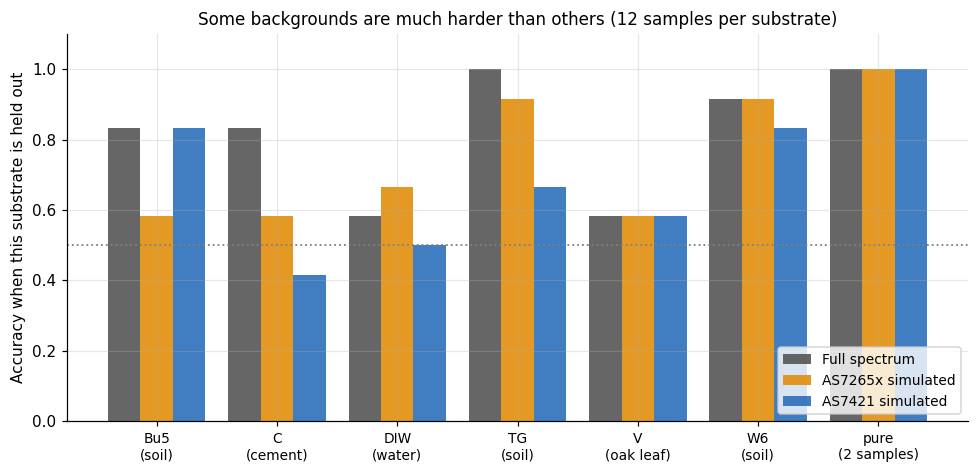

In [18]:
# Accuracy by held-out substrate (Stage 1, logistic regression): which backgrounds are hard?
subs = sorted(set(groups))
fig, ax = plt.subplots(figsize=(9, 4.4))
width = 0.27
for j, (fname, label, colour) in enumerate([("Full 850-2400 nm, reflectance (SNV)", "Full spectrum", COL["Full"]),
                                            ("AS7265x sim, channels (SNV)", "AS7265x simulated", COL["AS7265x"]),
                                            ("AS7421 sim, channels (SNV)", "AS7421 simulated", COL["AS7421"])]):
    mask, pred = stored_predictions[(STAGE1, fname, "LogReg")]
    accs = [(pred[groups[mask] == s] == y[mask][groups[mask] == s]).mean() for s in subs]
    ax.bar(np.arange(len(subs)) + (j - 1) * width, accs, width=width, color=colour, alpha=0.9, label=label)
names = {"Bu5": "Bu5\n(soil)", "W6": "W6\n(soil)", "TG": "TG\n(soil)", "C": "C\n(cement)", "V": "V\n(oak leaf)", "DIW": "DIW\n(water)", "pure": "pure\n(2 samples)"}
ax.set_xticks(range(len(subs))); ax.set_xticklabels([names[s] for s in subs], fontsize=9)
ax.axhline(0.5, color="grey", ls=":", lw=1.2); ax.set_ylim(0, 1.1); ax.set_ylabel("Accuracy when this substrate is held out")
ax.set_title("Some backgrounds are much harder than others (12 samples per substrate)")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout(); save_fig("07_accuracy_by_substrate.png"); plt.show()

## 10. Is the AS7421 really better than the AS7265x?

Both chips are simulated on the same samples, so their predictions can be compared pair by pair.
Count the samples where only the AS7421 is right (b) and the samples where only the AS7265x is right (c), then test whether b and c differ more than chance allows (exact two-sided binomial test).

In [19]:
rows = []
for stage in [STAGE1, STAGE2]:
    for model in ["LogReg", "RandomForest"]:
        mask, p_265 = stored_predictions[(stage, "AS7265x sim, channels (SNV)", model)]
        _, p_421 = stored_predictions[(stage, "AS7421 sim, channels (SNV)", model)]
        ok_265, ok_421 = p_265 == y[mask], p_421 == y[mask]
        b = int((ok_421 & ~ok_265).sum()); c = int((ok_265 & ~ok_421).sum())
        p_val = binomtest(b, b + c, 0.5).pvalue if (b + c) > 0 else 1.0
        rows.append({"scope": stage, "model": model, "AS7421 only right (b)": b, "AS7265x only right (c)": c,
                     "both right": int((ok_265 & ok_421).sum()), "both wrong": int((~ok_265 & ~ok_421).sum()),
                     "p-value (b vs c)": round(p_val, 3)})
paired = pd.DataFrame(rows)
paired.to_csv(os.path.join(RESULTS_DIR, "chip_paired_comparison.csv"), index=False)
print(paired.to_string(index=False))

                        scope        model  AS7421 only right (b)  AS7265x only right (c)  both right  both wrong  p-value (b vs c)
  Stage 1: all concentrations       LogReg                     10                      15          38          11             0.424
  Stage 1: all concentrations RandomForest                     11                      12          38          13             1.000
Stage 2: operational (>= 15%)       LogReg                      1                       0          21           4             1.000
Stage 2: operational (>= 15%) RandomForest                      2                       1          19           4             1.000


## 11. Findings, generated from the results above

In [20]:
def fmt(stage, feature, model="LogReg"):
    r = lookup(stage, feature, model)
    return f"{r.accuracy:.2f} ({int(r.correct)}/{int(r.n_samples)}, 95% CI {r.ci_low:.2f} to {r.ci_high:.2f})"

full_f, c265_f, c421_f = "Full 850-2400 nm, reflectance (SNV)", "AS7265x sim, channels (SNV)", "AS7421 sim, channels (SNV)"
p265_1 = lookup(STAGE1, c265_f).perm_p; p421_1 = lookup(STAGE1, c421_f).perm_p
p265_2 = lookup(STAGE2, c265_f).perm_p; p421_2 = lookup(STAGE2, c421_f).perm_p

print("FINDINGS (logistic regression, tested on unseen substrates)")
print("-" * 78)
print(f"All concentrations, n = {int(all_mask.sum())}")
print(f"  Full lab spectrum      : {fmt(STAGE1, full_f)}")
print(f"  AS7265x simulated      : {fmt(STAGE1, c265_f)}   chance p = {p265_1:.3f}")
print(f"  AS7421 simulated       : {fmt(STAGE1, c421_f)}   chance p = {p421_1:.3f}")
print(f"Operational scope (>= {OPERATIONAL_MIN_CONC:g}%), n = {int(operational_mask.sum())}")
print(f"  Full lab spectrum      : {fmt(STAGE2, full_f)}")
print(f"  AS7265x simulated      : {fmt(STAGE2, c265_f)}   chance p = {p265_2:.3f}")
print(f"  AS7421 simulated       : {fmt(STAGE2, c421_f)}   chance p = {p421_2:.3f}")
print()
best_chip = results[results["kind"].str.startswith("Chip")].sort_values("accuracy", ascending=False).iloc[0]
print(f"Best single chip-simulation result: {best_chip['feature set']} / {best_chip['model']} / {best_chip['stage']}: "
      f"{best_chip.accuracy:.2f} ({int(best_chip.correct)}/{int(best_chip.n_samples)}). Selected from {int((results['kind'].str.startswith('Chip')).sum())} chip runs, so it is optimistic.")
print("Paired chip comparison p-values:", paired["p-value (b vs c)"].tolist(), "(all large means no detectable difference between chips)")

FINDINGS (logistic regression, tested on unseen substrates)
------------------------------------------------------------------------------
All concentrations, n = 74
  Full lab spectrum      : 0.80 (59/74, 95% CI 0.69 to 0.87)
  AS7265x simulated      : 0.72 (53/74, 95% CI 0.60 to 0.81)   chance p = 0.010
  AS7421 simulated       : 0.65 (48/74, 95% CI 0.54 to 0.75)   chance p = 0.010
Operational scope (>= 15%), n = 26


  Full lab spectrum      : 0.92 (24/26, 95% CI 0.76 to 0.98)
  AS7265x simulated      : 0.81 (21/26, 95% CI 0.62 to 0.91)   chance p = 0.010
  AS7421 simulated       : 0.85 (22/26, 95% CI 0.66 to 0.94)   chance p = 0.010

Best single chip-simulation result: AS7421 sim, channel differences / RandomForest / Stage 2: operational (>= 15%): 0.92 (24/26). Selected from 24 chip runs, so it is optimistic.
Paired chip comparison p-values: [0.424, 1.0, 1.0, 1.0] (all large means no detectable difference between chips)


### How to read these findings

1. **Preliminary evidence of separability.** Under leave-one-substrate-out testing, the simulated reflectance channels of both chips classify PET vs PLA above chance, and better at high plastic concentration than at trace levels.
   Some derivative-based variants (for example AS7265x channel differences on all concentrations) are not distinguishable from chance.
2. **Concentration drives accuracy.** Accuracy rises with the share of plastic in the sample. For a sorter this means the sensor's field of view should be filled by the plastic piece, which is a design requirement, not a software trick.
3. **No reliable chip difference yet.** With 26 to 74 samples, the intervals of the AS7265x and AS7421 overlap and the paired test finds no significant difference.
   The direction even flips: the AS7265x scores higher on all concentrations and the AS7421 on the operational scope, which is what noise looks like.
   These data do not justify choosing a chip on accuracy. Availability and cost have to decide, until real sensor measurements exist.
4. **Derivative features are not shown to help.** Gains from derivative features are inside the error bars, and the best-looking rows use the library's lab-computed derivative, which a sensor cannot reproduce.
5. **The full spectrum tends to do better.** The lab reference usually scores higher than the simulated chips, consistent with most of the PET/PLA difference lying beyond 1050 nm, but the intervals overlap, so this is a tendency and not a proven gap.

### Limitations that must accompany any quoted number

- One pure PET and one pure PLA sample underlie all 74 rows. Nothing here tests different bottles, cups, colours, ageing or thickness.
- The spectra were pre-processed by the library authors (continuum removal, SNV on replicates, smoothing). A real sensor delivers raw counts, so absolute accuracy on hardware will be lower.
- Chips are simulated with ideal Gaussian bands. Real channels have different shapes, noise, drift and LED illumination.
- The library starts at 850 nm, so only 3 of the 18 AS7265x channels could be simulated, and 40 of the AS7421's channels.
- Many configurations were tried on small samples. Treat the best score as an upper estimate.
- Supplier listings suggest the AS7421 is discontinued. Confirm stock before designing around it.

### Next steps
1. Confirm with the supervisor whether any real PET and PLA items may be measured on the physical sensor, for testing only. Without hardware data nothing here is validated.
2. Check the raw ASD spectra in the Zenodo record for readings below 850 nm, which would allow more AS7265x channels to be simulated.
3. Add further PLA/PET spectral sources covering 400 to 1000 nm so that results do not rest on one pair of materials.
4. Re-run this notebook unchanged on any new data and compare against `results/all_results.csv`.